<a href="https://colab.research.google.com/github/sergioGarcia91/SeismicUP/blob/main/10b_PGA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Inicio

In [ ]:
!git clone https://github.com/sergioGarcia91/SeismicUP.git

Cloning into 'SeismicUP'...
remote: Enumerating objects: 648, done.
remote: Counting objects: 100% (104/104), done.
remote: Compressing objects: 100% (104/104), done.
remote: Total 648 (delta 52), reused 0 (delta 0), pack-reused 544 (from 2)
Receiving objects: 100% (648/648), 90.58 MiB | 23.10 MiB/s, done.
Resolving deltas: 100% (337/337), done.


In [ ]:
# para incluir la libreria clonada
import sys
sys.path.append("/content/SeismicUP")

import seismicup as sup

In [ ]:
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import AutoMinorLocator, LogLocator

# Cambiar Fuente

In [ ]:
sup.plots.get_TimesNewRoman_font()

# Gráfica

In [ ]:
ml = np.array([0.1, 1.0, 2.0, 3.0, 4.0, 5.0])

distanciaEpi = np.linspace(1, 200, 100) # km
profundidad = np.array([5]) # km

ml

array([0.1, 1. , 2. , 3. , 4. , 5. ])

In [ ]:
def PGA_Z_m03(Ml, Repi, H, X=0):
  log10_Repi = np.log10(Repi)
  C = -0.8831
  a = 0.7632
  b = -1.0754
  c = -0.0036
  sigma = 0.2717

  epsilon = X * sigma

  return C + a * Ml + b * log10_Repi + c * H + epsilon


<>:73: SyntaxWarning: invalid escape sequence '\p'
<>:73: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_6518/2402552602.py:73: SyntaxWarning: invalid escape sequence '\p'
  ax.set_title(f'Curvas de atenuación para $H={profundidad[0]:.0f}$ k ($\pm1\sigma$)')


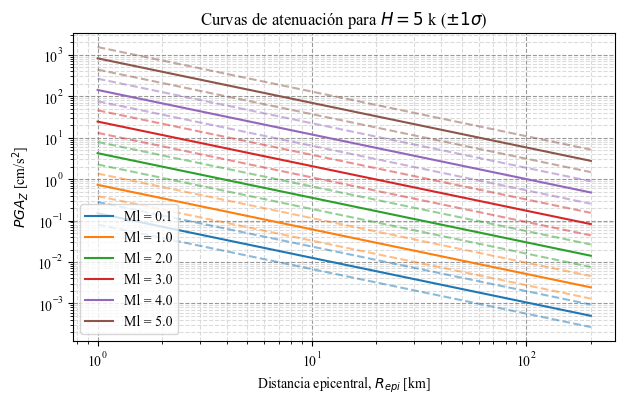

In [ ]:

fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(7,4))

for m in ml:
  pga_z_0 = PGA_Z_m03(Ml = m,
                      Repi= distanciaEpi,
                      H= profundidad[0],
                      X= 1)

  pga_z_0 = 10**pga_z_0

  pga_z_1 = PGA_Z_m03(Ml = m,
                    Repi= distanciaEpi,
                    H= profundidad[0],
                    X= 0)

  pga_z_1 = 10**pga_z_1

  pga_z_2 = PGA_Z_m03(Ml = m,
                    Repi= distanciaEpi,
                    H= profundidad[0],
                    X= -1)

  pga_z_2 = 10**pga_z_2


  line, = ax.plot(distanciaEpi,
          pga_z_0,
          ls='--',
          alpha=0.5)
  color = line.get_color()


  label_pga = f'Ml = {m}'

  ax.plot(distanciaEpi,
          pga_z_1,
          ls='-',
          label=label_pga,
          c=color)

  ax.plot(distanciaEpi,
          pga_z_2,
          ls='--',
          c=color,
          alpha=0.5)

ax.set_xscale('log')
ax.set_yscale('log')

#ax.set_xlim(90, 320)
# Eje X (logarítmico)
ax.xaxis.set_minor_locator(
    LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1)
)

# Eje Y (logarítmico)
ax.yaxis.set_minor_locator(LogLocator(base=10.0,
                                      subs=np.arange(2, 10) * 0.1))
# Activar los ticks menores
ax.minorticks_on()

# Grilla mayor
ax.grid(which='major', linestyle='--', color='gray', alpha=0.8)

# Grilla menor
ax.grid(which='minor', linestyle='--', color='lightgray', alpha=0.8)

ax.set_xlabel('Distancia epicentral, $R_{epi}$ [km]')
ax.set_ylabel(r"$PGA_Z$ [cm/s$^2$]")

plt.legend()

ax.set_title(f'Curvas de atenuación para $H={profundidad[0]:.0f}$ k ($\pm1\sigma$)')

plt.show()

In [ ]:
def PGA_Z_m03_mw(Mw, Repi, H, X=0):
  log10_Repi = np.log10(Repi)
  C = 4.2114
  a = 0.6723
  b = -3.4934
  c = 0.0053
  sigma = 0.2324

  epsilon = X * sigma

  return C + a * Mw + b * log10_Repi + c * H + epsilon

mw = np.array([0.1, 1.0, 2.0, 3.0, 4.0, 5.0])

distanciaEpi_mw = np.linspace(100, 300, 100) # km
profundidad_mw = np.array([5]) # km

<>:126: SyntaxWarning: invalid escape sequence '\p'
<>:126: SyntaxWarning: invalid escape sequence '\p'
/tmp/ipykernel_6518/777611689.py:126: SyntaxWarning: invalid escape sequence '\p'
  ax.set_title(f'Curvas de atenuación para $H={profundidad[0]:.0f}$ k ($\pm1\sigma$)')


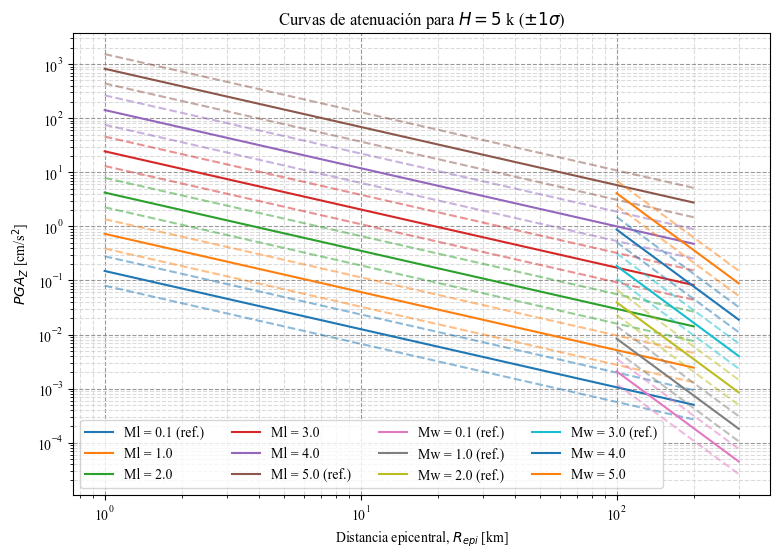

In [ ]:
fig, ax = plt.subplots(ncols=1, nrows=1, figsize=(9,6))

## Ml
for m in ml:
  pga_z_0 = PGA_Z_m03(Ml = m,
                      Repi= distanciaEpi,
                      H= profundidad[0],
                      X= 1)

  pga_z_0 = 10**pga_z_0

  pga_z_1 = PGA_Z_m03(Ml = m,
                    Repi= distanciaEpi,
                    H= profundidad[0],
                    X= 0)

  pga_z_1 = 10**pga_z_1

  pga_z_2 = PGA_Z_m03(Ml = m,
                    Repi= distanciaEpi,
                    H= profundidad[0],
                    X= -1)

  pga_z_2 = 10**pga_z_2


  line, = ax.plot(distanciaEpi,
          pga_z_0,
          ls='--',
          alpha=0.5)
  color = line.get_color()

  if 0.8 < m <=4.1:
    label_pga = f'Ml = {m}'
  else:
    label_pga = f'Ml = {m} (ref.)'

  #label_pga = f'Ml = {m}'

  ax.plot(distanciaEpi,
          pga_z_1,
          ls='-',
          label=label_pga,
          c=color)

  ax.plot(distanciaEpi,
          pga_z_2,
          ls='--',
          c=color,
          alpha=0.5)


## Mw
for m in mw:
  pga_z_0 = PGA_Z_m03_mw(Mw = m,
                      Repi= distanciaEpi_mw,
                      H= profundidad_mw[0],
                      X= 1)

  pga_z_0 = 10**pga_z_0

  pga_z_1 = PGA_Z_m03_mw(Mw = m,
                    Repi= distanciaEpi_mw,
                    H= profundidad_mw[0],
                    X= 0)

  pga_z_1 = 10**pga_z_1

  pga_z_2 = PGA_Z_m03_mw(Mw = m,
                    Repi= distanciaEpi_mw,
                    H= profundidad_mw[0],
                    X= -1)

  pga_z_2 = 10**pga_z_2


  line, = ax.plot(distanciaEpi_mw,
          pga_z_0,
          ls='--',
          alpha=0.5)
  color = line.get_color()

  if m >=3.6:
    label_pga = f'Mw = {m}'
  else:
    label_pga = f'Mw = {m} (ref.)'

  ax.plot(distanciaEpi_mw,
          pga_z_1,
          ls='-',
          label=label_pga,
          c=color)

  ax.plot(distanciaEpi_mw,
          pga_z_2,
          ls='--',
          c=color,
          alpha=0.5)

ax.set_xscale('log')
ax.set_yscale('log')

#ax.set_xlim(90, 320)
# Eje X (logarítmico)
ax.xaxis.set_minor_locator(
    LogLocator(base=10.0, subs=np.arange(2, 10) * 0.1)
)

# Eje Y (logarítmico)
ax.yaxis.set_minor_locator(LogLocator(base=10.0,
                                      subs=np.arange(2, 10) * 0.1))
# Activar los ticks menores
ax.minorticks_on()

# Grilla mayor
ax.grid(which='major', linestyle='--', color='gray', alpha=0.8)

# Grilla menor
ax.grid(which='minor', linestyle='--', color='lightgray', alpha=0.8)

ax.set_xlabel('Distancia epicentral, $R_{epi}$ [km]')
ax.set_ylabel(r"$PGA_Z$ [cm/s$^2$]")

plt.legend(ncols=4)

ax.set_title(f'Curvas de atenuación para $H={profundidad[0]:.0f}$ k ($\pm1\sigma$)')

plt.show()

# Cargar CSV

In [ ]:
df_ = pd.read_csv('20260718_Eventos_VMM_radio150km_v3_ajustado.csv',
                  sep=';',
                  decimal=',')

df_ = df_[df_['validas'] == 1].copy()
new_row = pd.DataFrame({
    'Región': ['BRJC'],
    'Latitud': [6.97],
    'Longitud': [-73.74],
    'Profundidad [km]': [108]
})

df_ = pd.concat([df_, new_row], ignore_index=True)

df_.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Data columns (total 22 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Fecha-Hora UTC          366 non-null    object 
 1   Latitud                 367 non-null    float64
 2   Longitud                367 non-null    float64
 3   Profundidad [km]        367 non-null    float64
 4   Magnitud                366 non-null    float64
 5   Tipo Magnitud           366 non-null    object 
 6   Error Latitud [km]      366 non-null    float64
 7   Error Longitud [km]     366 non-null    float64
 8   Error Profundidad [km]  366 non-null    float64
 9   Numero de Fases         304 non-null    float64
 10  RMS [seg]               366 non-null    float64
 11  Gap                     366 non-null    float64
 12  PGV EW (cm/s)           366 non-null    float64
 13  PGV NS (cm/s)           364 non-null    float64
 14  PGV Z (cm/s)            364 non-null    fl

# Geodataframe

In [ ]:
# Incluir las coordenadsa para georfrenciar la estacion

In [ ]:
gdf_unido = gpd.GeoDataFrame(
    df_, geometry=gpd.points_from_xy(df_.Longitud, df_.Latitud), crs="EPSG:4326"
)

<Axes: >

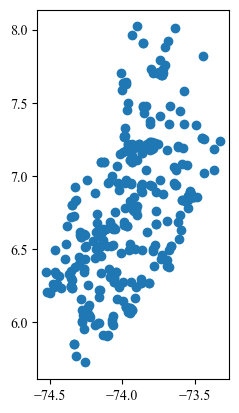

In [ ]:
gdf_unido.plot()

<Axes: >

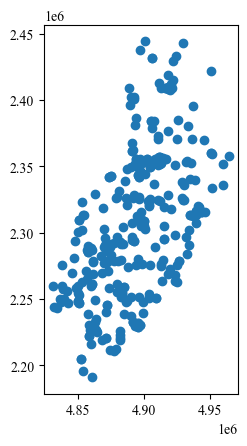

In [ ]:
gdf_unido = gdf_unido.to_crs(9377)

gdf_unido.plot()

## Obtener X y Y

In [ ]:
gdf_unido.get_coordinates()

,x,y
0,4.897212e+06,2.438131e+06
1,4.880526e+06,2.278908e+06
2,4.871811e+06,2.286553e+06
3,4.924937e+06,2.263028e+06
4,4.920305e+06,2.412445e+06
...,...,...
362,4.872161e+06,2.245438e+06
363,4.863383e+06,2.227774e+06
364,4.860510e+06,2.229660e+06
365,4.885309e+06,2.238669e+06


In [ ]:
df_['X [km]'] = gdf_unido.get_coordinates()['x'] / 1000
df_['Y [km]'] = gdf_unido.get_coordinates()['y'] / 1000

df_.tail()

,Fecha-Hora UTC,Latitud,Longitud,Profundidad [km],Magnitud,Tipo Magnitud,Error Latitud [km],Error Longitud [km],Error Profundidad [km],Numero de Fases,...,PGV Z (cm/s),PGA EW (cm/s^2),PGA NS (cm/s^2),PGA Z (cm/s^2),Fecha,validas_old,validas,Región,X [km],Y [km]
362,22/08/2018 13:06,6.220,-74.156,20.00,4.1,MLr_vmm,1.061,1.061,3.9,NaN,...,0.035654,NaN,NaN,NaN,20180822-13,1.0,1.0,NaN,4872.161005,2245.438098
363,9/08/2018 0:13,6.060,-74.235,1.85,2.2,MLr_vmm,1.202,1.202,3.2,38.0,...,0.000681,NaN,NaN,NaN,20180809-00,1.0,1.0,NaN,4863.382540,2227.774052
364,8/08/2018 21:54,6.077,-74.261,0.00,3.1,MLr_vmm,1.131,1.131,2.8,83.0,...,0.005409,NaN,NaN,NaN,20180808-21,1.0,1.0,NaN,4860.510303,2229.659585
365,7/08/2018 20:12,6.159,-74.037,6.66,2.6,MLr_vmm,1.202,1.202,3.1,20.0,...,0.001830,NaN,NaN,NaN,20180807-20,1.0,1.0,NaN,4885.309239,2238.669298
366,NaN,6.970,-73.740,108.00,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,BRJC,4918.291520,2328.237740


In [ ]:
df_.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 367 entries, 0 to 366
Data columns (total 24 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Fecha-Hora UTC          366 non-null    object 
 1   Latitud                 367 non-null    float64
 2   Longitud                367 non-null    float64
 3   Profundidad [km]        367 non-null    float64
 4   Magnitud                366 non-null    float64
 5   Tipo Magnitud           366 non-null    object 
 6   Error Latitud [km]      366 non-null    float64
 7   Error Longitud [km]     366 non-null    float64
 8   Error Profundidad [km]  366 non-null    float64
 9   Numero de Fases         304 non-null    float64
 10  RMS [seg]               366 non-null    float64
 11  Gap                     366 non-null    float64
 12  PGV EW (cm/s)           366 non-null    float64
 13  PGV NS (cm/s)           364 non-null    float64
 14  PGV Z (cm/s)            364 non-null    fl

# DF PGA

In [ ]:
df_.columns

Index(['Fecha-Hora UTC', 'Latitud', 'Longitud', 'Profundidad [km]', 'Magnitud',
       'Tipo Magnitud', 'Error Latitud [km]', 'Error Longitud [km]',
       'Error Profundidad [km]', 'Numero de Fases', 'RMS [seg]', 'Gap',
       'PGV EW (cm/s)', 'PGV NS (cm/s)', 'PGV Z (cm/s)', 'PGA EW (cm/s^2)',
       'PGA NS (cm/s^2)', 'PGA Z (cm/s^2)', 'Fecha', 'validas_old', 'validas',
       'Región', 'X [km]', 'Y [km]'],
      dtype='object')

In [ ]:
df_PGA = df_[['X [km]', 'Error Longitud [km]', 'Y [km]', 'Error Latitud [km]',
       'Profundidad [km]', 'Error Profundidad [km]', 'Magnitud',
       'Tipo Magnitud', 'PGA EW (cm/s^2)', 'PGA NS (cm/s^2)',
       'PGA Z (cm/s^2)', ]].copy()
df_PGA = df_PGA.iloc[:-1]

df_BRJC = df_.iloc[-1].copy()
df_BRJC = df_BRJC[['X [km]', 'Y [km]', 'Profundidad [km]']]

print(df_BRJC, '\n')

df_PGA

X [km]              4918.29152
Y [km]              2328.23774
Profundidad [km]         108.0
Name: 366, dtype: object 



,X [km],Error Longitud [km],Y [km],Error Latitud [km],Profundidad [km],Error Profundidad [km],Magnitud,Tipo Magnitud,PGA EW (cm/s^2),PGA NS (cm/s^2),PGA Z (cm/s^2)
0,4897.211907,1.202,2438.131223,1.202,17.45,2.6,2.0,MLr_vmm,0.014514,0.019603,0.01082
1,4880.526181,0.636,2278.907747,0.636,25.74,2.5,2.2,MLr_vmm,NaN,NaN,NaN
2,4871.811481,0.636,2286.553202,0.636,12.51,2.9,2.3,MLr_vmm,NaN,NaN,NaN
3,4924.937454,0.990,2263.027651,0.990,12.80,2.4,3.2,MLr_vmm,NaN,NaN,NaN
4,4920.304673,0.849,2412.445406,0.849,24.16,2.7,2.2,MLr_vmm,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
361,4872.050403,1.061,2245.438340,1.061,20.09,3.9,4.1,MLr_vmm,NaN,NaN,NaN
362,4872.161005,1.061,2245.438098,1.061,20.00,3.9,4.1,MLr_vmm,NaN,NaN,NaN
363,4863.382540,1.202,2227.774052,1.202,1.85,3.2,2.2,MLr_vmm,NaN,NaN,NaN
364,4860.510303,1.131,2229.659585,1.131,0.00,2.8,3.1,MLr_vmm,NaN,NaN,NaN


# Homogeneizar magnitudes

In [ ]:
# no todas son Mw ... se va usar la formula del SGC para pasar a Mw
# considerar para la de Campo Colorado usar mejor Ml
# que ya lo entrega así el SGC
df_PGA['Tipo Magnitud'].unique()

array(['MLr_vmm', 'MLr_2', 'MLr_3'], dtype=object)

In [ ]:
# Casi todas dicen Ml ... para M no aparece una formula
# se va usar la misma de Ml
# Mw (2.9 <Ml <= 6.1) = 0.958*Ml + 0.1
df_PGA['Ml'] = df_PGA['Magnitud'].copy()

df_PGA.head(10)

,X [km],Error Longitud [km],Y [km],Error Latitud [km],Profundidad [km],Error Profundidad [km],Magnitud,Tipo Magnitud,PGA EW (cm/s^2),PGA NS (cm/s^2),PGA Z (cm/s^2),Ml
0,4897.211907,1.202,2438.131223,1.202,17.45,2.6,2.0,MLr_vmm,0.014514,0.019603,0.010820,2.0
1,4880.526181,0.636,2278.907747,0.636,25.74,2.5,2.2,MLr_vmm,NaN,NaN,NaN,2.2
2,4871.811481,0.636,2286.553202,0.636,12.51,2.9,2.3,MLr_vmm,NaN,NaN,NaN,2.3
3,4924.937454,0.990,2263.027651,0.990,12.80,2.4,3.2,MLr_vmm,NaN,NaN,NaN,3.2
4,4920.304673,0.849,2412.445406,0.849,24.16,2.7,2.2,MLr_vmm,NaN,NaN,NaN,2.2
5,4872.992970,0.919,2271.519406,0.919,19.80,4.4,2.1,MLr_vmm,NaN,NaN,NaN,2.1
6,4923.721953,0.990,2263.471295,0.990,28.53,2.8,1.7,MLr_vmm,0.013329,0.014441,0.010000,1.7
7,4890.951517,0.919,2296.679610,0.919,0.00,2.7,1.7,MLr_vmm,0.049640,0.054520,0.027843,1.7
8,4839.986779,0.778,2250.159739,0.778,34.36,1.9,2.7,MLr_vmm,0.060199,0.059235,0.043127,2.7
9,4856.836077,0.778,2265.258057,0.778,13.30,2.8,2.0,MLr_vmm,0.023789,0.029937,0.016212,2.0


In [ ]:
df_PGA_aumentado = df_PGA.copy()

# Calculo parametros para PGA

In [ ]:
df_BRJC

,366
X [km],4918.29152
Y [km],2328.23774
Profundidad [km],108.0


In [ ]:
# Distancia eventos a la estacion BRJC
df_PGA_aumentado['Dist Epi [km]'] = np.sqrt(
    (df_PGA_aumentado['X [km]'] - df_BRJC['X [km]'])**2 +
    (df_PGA_aumentado['Y [km]'] - df_BRJC['Y [km]'])**2)

df_PGA_aumentado['Dist Hip [km]'] = np.sqrt(
    (df_PGA_aumentado['X [km]'] - df_BRJC['X [km]'])**2 +
    (df_PGA_aumentado['Y [km]'] - df_BRJC['Y [km]'])**2 +
    (df_PGA_aumentado['Profundidad [km]'] - df_BRJC['Profundidad [km]'])**2)

df_PGA_aumentado.describe().round(2)

,X [km],Error Longitud [km],Y [km],Error Latitud [km],Profundidad [km],Error Profundidad [km],Magnitud,PGA EW (cm/s^2),PGA NS (cm/s^2),PGA Z (cm/s^2),Ml,Dist Epi [km],Dist Hip [km]
count,366.00,366.00,366.00,366.00,366.00,366.00,366.00,311.00,311.00,311.00,366.00,366.00,366.00
mean,4895.94,0.96,2310.26,0.96,17.07,2.38,1.94,0.30,0.34,0.18,1.94,58.86,111.64
std,27.53,0.40,54.63,0.41,13.03,1.04,0.59,1.31,1.36,0.69,0.59,33.06,23.05
min,4831.39,0.28,2190.98,0.28,-2.00,0.60,0.80,0.01,0.01,0.01,0.80,7.41,60.83
25%,4875.40,0.71,2264.01,0.71,6.03,1.60,1.60,0.03,0.03,0.02,1.60,28.48,93.39
50%,4897.35,0.92,2312.83,0.92,17.06,2.20,1.90,0.06,0.06,0.04,1.90,51.74,109.02
75%,4912.27,1.06,2354.00,1.06,26.75,2.88,2.20,0.13,0.15,0.08,2.20,83.85,125.58
max,4964.03,5.66,2444.42,5.66,58.35,8.20,4.10,15.13,13.46,7.00,4.10,148.79,184.75


# Modelos PGA empiricos Notebook 09

In [ ]:
def PGA_EW_m03(Ml, Repi, H, X=0):
  log10_Repi = np.log10(Repi)
  C = -0.8917
  a = 0.7978
  b = -1.0036
  c = -0.0030
  sigma = 0.2945

  epsilon = X * sigma

  return C + a * Ml + b * log10_Repi + c * H + epsilon

def PGA_NS_m03(Ml, Repi, H, X=0):
  log10_Repi = np.log10(Repi)
  C = -0.8966
  a = 0.8072
  b = -0.9856
  c = -0.0037
  sigma = 0.3027

  epsilon = X * sigma

  return C + a * Ml + b * log10_Repi + c * H + epsilon

def PGA_Z_m03(Ml, Repi, H, X=0):
  log10_Repi = np.log10(Repi)
  C = -0.8831
  a = 0.7632
  b = -1.0754
  c = -0.0036
  sigma = 0.2717

  epsilon = X * sigma

  return C + a * Ml + b * log10_Repi + c * H + epsilon

In [ ]:
df_PGA_aumentado.columns

Index(['X [km]', 'Error Longitud [km]', 'Y [km]', 'Error Latitud [km]',
       'Profundidad [km]', 'Error Profundidad [km]', 'Magnitud',
       'Tipo Magnitud', 'PGA EW (cm/s^2)', 'PGA NS (cm/s^2)', 'PGA Z (cm/s^2)',
       'Ml', 'Dist Epi [km]', 'Dist Hip [km]'],
      dtype='object')

In [ ]:
df_PGA_aumentado['PGA_EW_cal'] = PGA_EW_m03(Ml = df_PGA_aumentado['Ml'],
                                            Repi= df_PGA_aumentado['Dist Epi [km]'],
                                            H= df_PGA_aumentado['Profundidad [km]'],
                                            X= 0)
df_PGA_aumentado['Residual_EW'] = np.log10(df_PGA_aumentado['PGA EW (cm/s^2)']) - df_PGA_aumentado['PGA_EW_cal']
df_PGA_aumentado['PGA_EW_cal'] = 10**df_PGA_aumentado['PGA_EW_cal']

df_PGA_aumentado['PGA_NS_cal'] = PGA_NS_m03(Ml = df_PGA_aumentado['Ml'],
                                            Repi= df_PGA_aumentado['Dist Epi [km]'],
                                            H= df_PGA_aumentado['Profundidad [km]'],
                                            X= 0)
df_PGA_aumentado['Residual_NS'] = np.log10(df_PGA_aumentado['PGA NS (cm/s^2)']) - df_PGA_aumentado['PGA_NS_cal']
df_PGA_aumentado['PGA_NS_cal'] = 10**df_PGA_aumentado['PGA_NS_cal']

df_PGA_aumentado['PGA_Z_cal'] = PGA_Z_m03(Ml = df_PGA_aumentado['Ml'],
                                          Repi= df_PGA_aumentado['Dist Epi [km]'],
                                          H= df_PGA_aumentado['Profundidad [km]'],
                                          X= 0)
df_PGA_aumentado['Residual_Z'] = np.log10(df_PGA_aumentado['PGA Z (cm/s^2)']) - df_PGA_aumentado['PGA_Z_cal']
df_PGA_aumentado['PGA_Z_cal'] = 10**df_PGA_aumentado['PGA_Z_cal']

## Plots

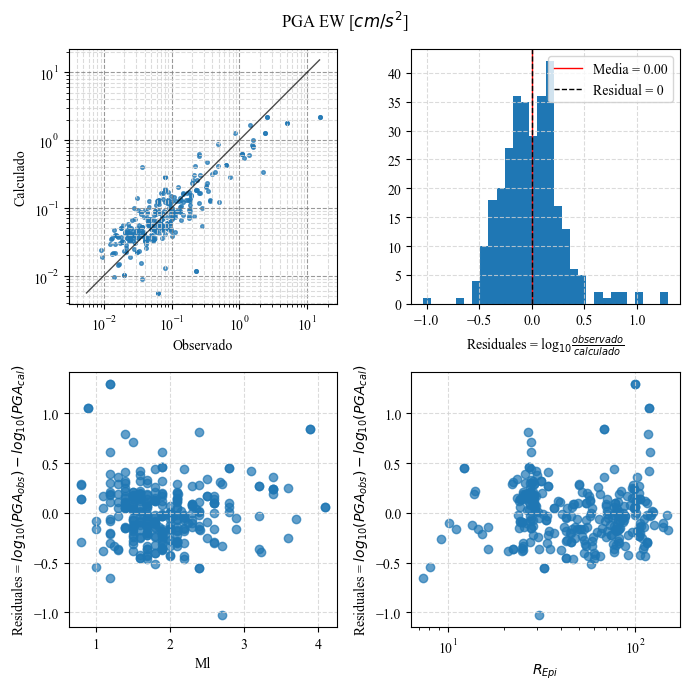

In [ ]:
# Límites comunes para ambos ejes
xmin = min(df_PGA_aumentado['PGA EW (cm/s^2)'].min(),
           df_PGA_aumentado['PGA_EW_cal'].min())

xmax = max(df_PGA_aumentado['PGA EW (cm/s^2)'].max(),
           df_PGA_aumentado['PGA_EW_cal'].max())

fig, ax = plt.subplots(ncols=2, nrows=2, figsize=(7,7))

ax[0,0].scatter(df_PGA_aumentado['PGA EW (cm/s^2)'],
           df_PGA_aumentado['PGA_EW_cal'],
           s=7,
           alpha=0.7)

# Línea 1:1
ax[0,0].plot([xmin, xmax],
        [xmin, xmax],
        'k-',
        lw=1,
        alpha=0.7,
        label='y = x')

ax[0,0].set_xscale('log')
ax[0,0].set_yscale('log')

ax[0,0].set_xlim(xmin, xmax)
ax[0,0].set_ylim(xmin, xmax)

# Grilla mayor
ax[0,0].grid(which='major', linestyle='--', color='gray', alpha=0.8)

# Grilla menor
ax[0,0].grid(which='minor', linestyle='--', color='lightgray', alpha=0.8)

ax[0,0].set_xlabel('Observado')
ax[0,0].set_ylabel('Calculado')
ax[0,0].axis('equal')

# Histograma Residuales
ax[0,1].hist(df_PGA_aumentado['Residual_EW'],
           bins=30)
ax[0,1].grid(linestyle='--', color='lightgray', alpha=0.8)
ax[0,1].set_xlabel(r'Residuales = log$_{10}\frac{observado}{calculado}$')
ax[0,1].axvline(df_PGA_aumentado['Residual_EW'].mean(),
              color='r',
              lw=1,
              label=f'Media = {df_PGA_aumentado["Residual_EW"].mean():.2f}')

ax[0,1].axvline(0,
              color='k',
              linestyle='--',
              lw=1,
              label='Residual = 0')
ax[0,1].legend()


# Residuales frente al Ml
ax[1,0].scatter(
    df_PGA_aumentado['Ml'],
    df_PGA_aumentado['Residual_EW'],
    alpha=0.7
)
ax[1,0].set_xlabel('Ml')
ax[1,0].set_ylabel(r'Residuales = $log_{10}​(PGA_{obs}​)−log_{10}​(PGA_{cal}​)$')
ax[1,0].grid(linestyle='--', color='lightgray', alpha=0.8)

# Residuales frente al REpi
ax[1,1].scatter(
    df_PGA_aumentado['Dist Epi [km]'],
    df_PGA_aumentado['Residual_EW'],
    alpha=0.7
)
ax[1,1].set_xscale('log')
ax[1,1].set_xlabel('$R_{Epi}$')
ax[1,1].set_ylabel(r'Residuales = $log_{10}​(PGA_{obs}​)−log_{10}​(PGA_{cal}​)$')
ax[1,1].grid(linestyle='--', color='lightgray', alpha=0.8)

plt.suptitle('PGA EW [$cm/s^2$]')

plt.tight_layout()

plt.show()

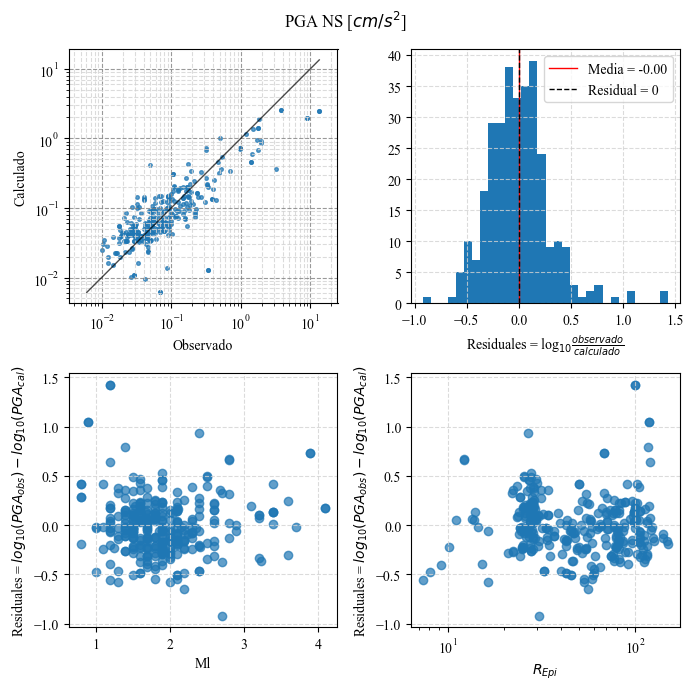

In [ ]:
# Límites comunes para ambos ejes
xmin = min(df_PGA_aumentado['PGA NS (cm/s^2)'].min(),
           df_PGA_aumentado['PGA_NS_cal'].min())

xmax = max(df_PGA_aumentado['PGA NS (cm/s^2)'].max(),
           df_PGA_aumentado['PGA_NS_cal'].max())

fig, ax = plt.subplots(ncols=2, nrows=2, figsize=(7,7))

ax[0,0].scatter(df_PGA_aumentado['PGA NS (cm/s^2)'],
           df_PGA_aumentado['PGA_NS_cal'],
           s=7,
           alpha=0.7)

# Línea 1:1
ax[0,0].plot([xmin, xmax],
        [xmin, xmax],
        'k-',
        lw=1,
        alpha=0.7,
        label='y = x')

ax[0,0].set_xscale('log')
ax[0,0].set_yscale('log')

ax[0,0].set_xlim(xmin, xmax)
ax[0,0].set_ylim(xmin, xmax)

# Grilla mayor
ax[0,0].grid(which='major', linestyle='--', color='gray', alpha=0.8)

# Grilla menor
ax[0,0].grid(which='minor', linestyle='--', color='lightgray', alpha=0.8)

ax[0,0].set_xlabel('Observado')
ax[0,0].set_ylabel('Calculado')
ax[0,0].axis('equal')

# Histograma Residuales
ax[0,1].hist(df_PGA_aumentado['Residual_NS'],
           bins=30)
ax[0,1].grid(linestyle='--', color='lightgray', alpha=0.8)
ax[0,1].set_xlabel(r'Residuales = log$_{10}\frac{observado}{calculado}$')
ax[0,1].axvline(df_PGA_aumentado['Residual_NS'].mean(),
              color='r',
              lw=1,
              label=f'Media = {df_PGA_aumentado["Residual_NS"].mean():.2f}')

ax[0,1].axvline(0,
              color='k',
              linestyle='--',
              lw=1,
              label='Residual = 0')
ax[0,1].legend()


# Residuales frente al Ml
ax[1,0].scatter(
    df_PGA_aumentado['Ml'],
    df_PGA_aumentado['Residual_NS'],
    alpha=0.7
)
ax[1,0].set_xlabel('Ml')
ax[1,0].set_ylabel(r'Residuales = $log_{10}​(PGA_{obs}​)−log_{10}​(PGA_{cal}​)$')
ax[1,0].grid(linestyle='--', color='lightgray', alpha=0.8)

# Residuales frente al REpi
ax[1,1].scatter(
    df_PGA_aumentado['Dist Epi [km]'],
    df_PGA_aumentado['Residual_NS'],
    alpha=0.7
)
ax[1,1].set_xscale('log')
ax[1,1].set_xlabel('$R_{Epi}$')
ax[1,1].set_ylabel(r'Residuales = $log_{10}​(PGA_{obs}​)−log_{10}​(PGA_{cal}​)$')
ax[1,1].grid(linestyle='--', color='lightgray', alpha=0.8)

plt.suptitle('PGA NS [$cm/s^2$]')

plt.tight_layout()

plt.show()

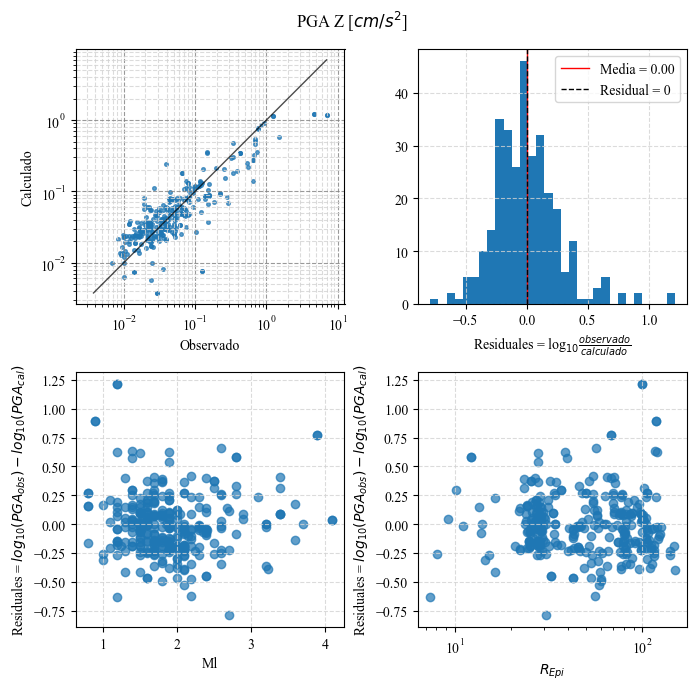

In [ ]:
# Límites comunes para ambos ejes
xmin = min(df_PGA_aumentado['PGA Z (cm/s^2)'].min(),
           df_PGA_aumentado['PGA_Z_cal'].min())

xmax = max(df_PGA_aumentado['PGA Z (cm/s^2)'].max(),
           df_PGA_aumentado['PGA_Z_cal'].max())

fig, ax = plt.subplots(ncols=2, nrows=2, figsize=(7,7))

ax[0,0].scatter(df_PGA_aumentado['PGA Z (cm/s^2)'],
           df_PGA_aumentado['PGA_Z_cal'],
           s=7,
           alpha=0.7)

# Línea 1:1
ax[0,0].plot([xmin, xmax],
        [xmin, xmax],
        'k-',
        lw=1,
        alpha=0.7,
        label='y = x')

ax[0,0].set_xscale('log')
ax[0,0].set_yscale('log')

ax[0,0].set_xlim(xmin, xmax)
ax[0,0].set_ylim(xmin, xmax)

# Grilla mayor
ax[0,0].grid(which='major', linestyle='--', color='gray', alpha=0.8)

# Grilla menor
ax[0,0].grid(which='minor', linestyle='--', color='lightgray', alpha=0.8)

ax[0,0].set_xlabel('Observado')
ax[0,0].set_ylabel('Calculado')
ax[0,0].axis('equal')

# Histograma Residuales
ax[0,1].hist(df_PGA_aumentado['Residual_Z'],
           bins=30)
ax[0,1].grid(linestyle='--', color='lightgray', alpha=0.8)
ax[0,1].set_xlabel(r'Residuales = log$_{10}\frac{observado}{calculado}$')
ax[0,1].axvline(df_PGA_aumentado['Residual_Z'].mean(),
              color='r',
              lw=1,
              label=f'Media = {df_PGA_aumentado["Residual_Z"].mean():.2f}')

ax[0,1].axvline(0,
              color='k',
              linestyle='--',
              lw=1,
              label='Residual = 0')
ax[0,1].legend()


# Residuales frente al Ml
ax[1,0].scatter(
    df_PGA_aumentado['Ml'],
    df_PGA_aumentado['Residual_Z'],
    alpha=0.7
)
ax[1,0].set_xlabel('Ml')
ax[1,0].set_ylabel(r'Residuales = $log_{10}​(PGA_{obs}​)−log_{10}​(PGA_{cal}​)$')
ax[1,0].grid(linestyle='--', color='lightgray', alpha=0.8)

# Residuales frente al REpi
ax[1,1].scatter(
    df_PGA_aumentado['Dist Epi [km]'],
    df_PGA_aumentado['Residual_Z'],
    alpha=0.7
)
ax[1,1].set_xscale('log')
ax[1,1].set_xlabel('$R_{Epi}$')
ax[1,1].set_ylabel(r'Residuales = $log_{10}​(PGA_{obs}​)−log_{10}​(PGA_{cal}​)$')
ax[1,1].grid(linestyle='--', color='lightgray', alpha=0.8)

plt.suptitle('PGA Z [$cm/s^2$]')

plt.tight_layout()

plt.show()

# Fin